# NB2. Compromiso por margen y escalera solar

Este cuaderno continua el caso continuo de NB1. Aqui se responden dos preguntas. La primera es cuanto servicio caliente y cuanto calor recuperado se intercambian cuando se abre la aproximacion minima. La segunda es cuanto servicio caliente puede desplazar una fuente solar en cada nivel de suministro.

El area NO es una magnitud de este cuaderno. El area de la red exige el dimensionamiento unidad por unidad con diferencia de temperatura media logaritmica y se mide en NB5. Cada cifra que aparece en pantalla proviene de un campo de un objeto devuelto por el paquete `ship_toolkit`, sin aritmetica en celda.

In [27]:
# Public wheel asset of pre-release v0.2.1, verified by real download: 705792 bytes,
# SHA-256 0861A3AF5E2A5AED69DE236596FD42675B3240ED0AAB9DB18252B84B05CBCA9A.
WHEEL_URL = "https://github.com/iwolde/ship-toolkit-releases/releases/download/v0.2.1/ship_toolkit-0.2.1-py3-none-any.whl"

_REQUIRED = "0.2.1"

import importlib.metadata
import importlib.util
import subprocess
import sys

try:
    _version = importlib.metadata.version("ship-toolkit")
except importlib.metadata.PackageNotFoundError:
    _version = None

if importlib.util.find_spec("ship_toolkit") is None or (
    _version is not None and _version != _REQUIRED
):
    if not WHEEL_URL:
        raise RuntimeError("WHEEL_URL is empty: the wheel has not been published yet.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", WHEEL_URL], check=True)
    try:
        _version = importlib.metadata.version("ship-toolkit")
    except importlib.metadata.PackageNotFoundError:
        _version = None

if _version is None:
    import ship_toolkit
    _version = getattr(ship_toolkit, "__version__", "sin version")

print("ship-toolkit", _version)

ship-toolkit 0.2.1


## Como se ejecuta este cuaderno

En Colab la celda de preparacion instala el paquete desde el wheel de la pre-release cuando `WHEEL_URL` tiene valor.

Los datos llegan por `data_path` desde el paquete instalado. No se sube ningun archivo a mano y no se lee de Google Drive.

En ejecucion local desde el repositorio la celda de preparacion no instala nada.

In [29]:
from ship_toolkit import (
    apply_style,
    data_path,
    load_streams,
    plot_solar_staircase,
    plot_tradeoff,
    run_pinch,
    solar_staircase,
    sweep_dt_min,
)

apply_style()

## S1. El barrido de aproximacion minima

Abrir la aproximacion minima eleva el servicio caliente, disminuye la recuperacion interna y eleva el servicio frio. El resto del caso permanece fijo. `sweep_dt_min` recorre la aproximacion minima y devuelve una fila por valor, con las utilidades, el nivel de pliegue corrido, la cantidad de contactos, la cantidad de bolsillos y el invariante de Primera Ley del proceso.

In [31]:
streams = load_streams(data_path("c53_continuous_streams.csv"))
result = run_pinch(streams, dT_min=10.0, dt_cont_K=5.0)
sweep_table = sweep_dt_min(streams)

In [32]:
print(sweep_table[["dT_min_K", "Qh_kW", "Qc_kW", "Qr_kW", "pinch_shifted_C", "n_contacts", "n_pockets", "qh_minus_qc_kW"]].to_string(index=False))

 dT_min_K  Qh_kW  Qc_kW  Qr_kW  pinch_shifted_C  n_contacts  n_pockets  qh_minus_qc_kW
      2.0  183.0    0.0 1360.0            112.0           1          2           183.0
      3.0  183.0    0.0 1360.0            112.5           1          2           183.0
      4.0  183.0    0.0 1360.0            113.0           1          3           183.0
      5.0  183.0    0.0 1360.0            113.5           1          3           183.0
      6.0  183.0    0.0 1360.0            114.0           1          3           183.0
      7.0  183.0    0.0 1360.0            114.5           1          3           183.0
      8.0  187.0    4.0 1356.0            121.0           1          3           183.0
      9.0  201.0   18.0 1342.0            121.5           1          2           183.0
     10.0  215.0   32.0 1328.0            122.0           1          2           183.0
     11.0  229.0   46.0 1314.0            122.5           1          2           183.0
     12.0  243.0   60.0 1300.0            1

## S2. Lectura de la tabla

El invariante de Primera Ley se sostiene en todo el barrido: la diferencia entre servicio caliente y servicio frio vale 183.0 kW en cada punto, porque el deficit neto del proceso no depende de la aproximacion que se elija. Las tres filas certificadas del caso son las de 2 K, 10 K y 30 K, con 183.0, 215.0 y 495.0 kW de servicio caliente, 0.0, 32.0 y 312.0 kW de servicio frio, y 112.0, 122.0 y 132.0 °C de pliegue corrido.

La cantidad de contactos de pliegue es 1 en cada punto: el pliegue es puntual en todo el barrido. El conteo de bolsas no es monotono con la aproximacion: vale 2 en 2 K, sube a 3 en la banda de 4 a 8 K, vuelve a 2 entre 9 y 23 K y cae a 1 desde 24 K. El cuaderno imprime la columna medida y no la suaviza: el conteo de bolsas es un rasgo geometrico de la curva, no un indicador monotono del margen.

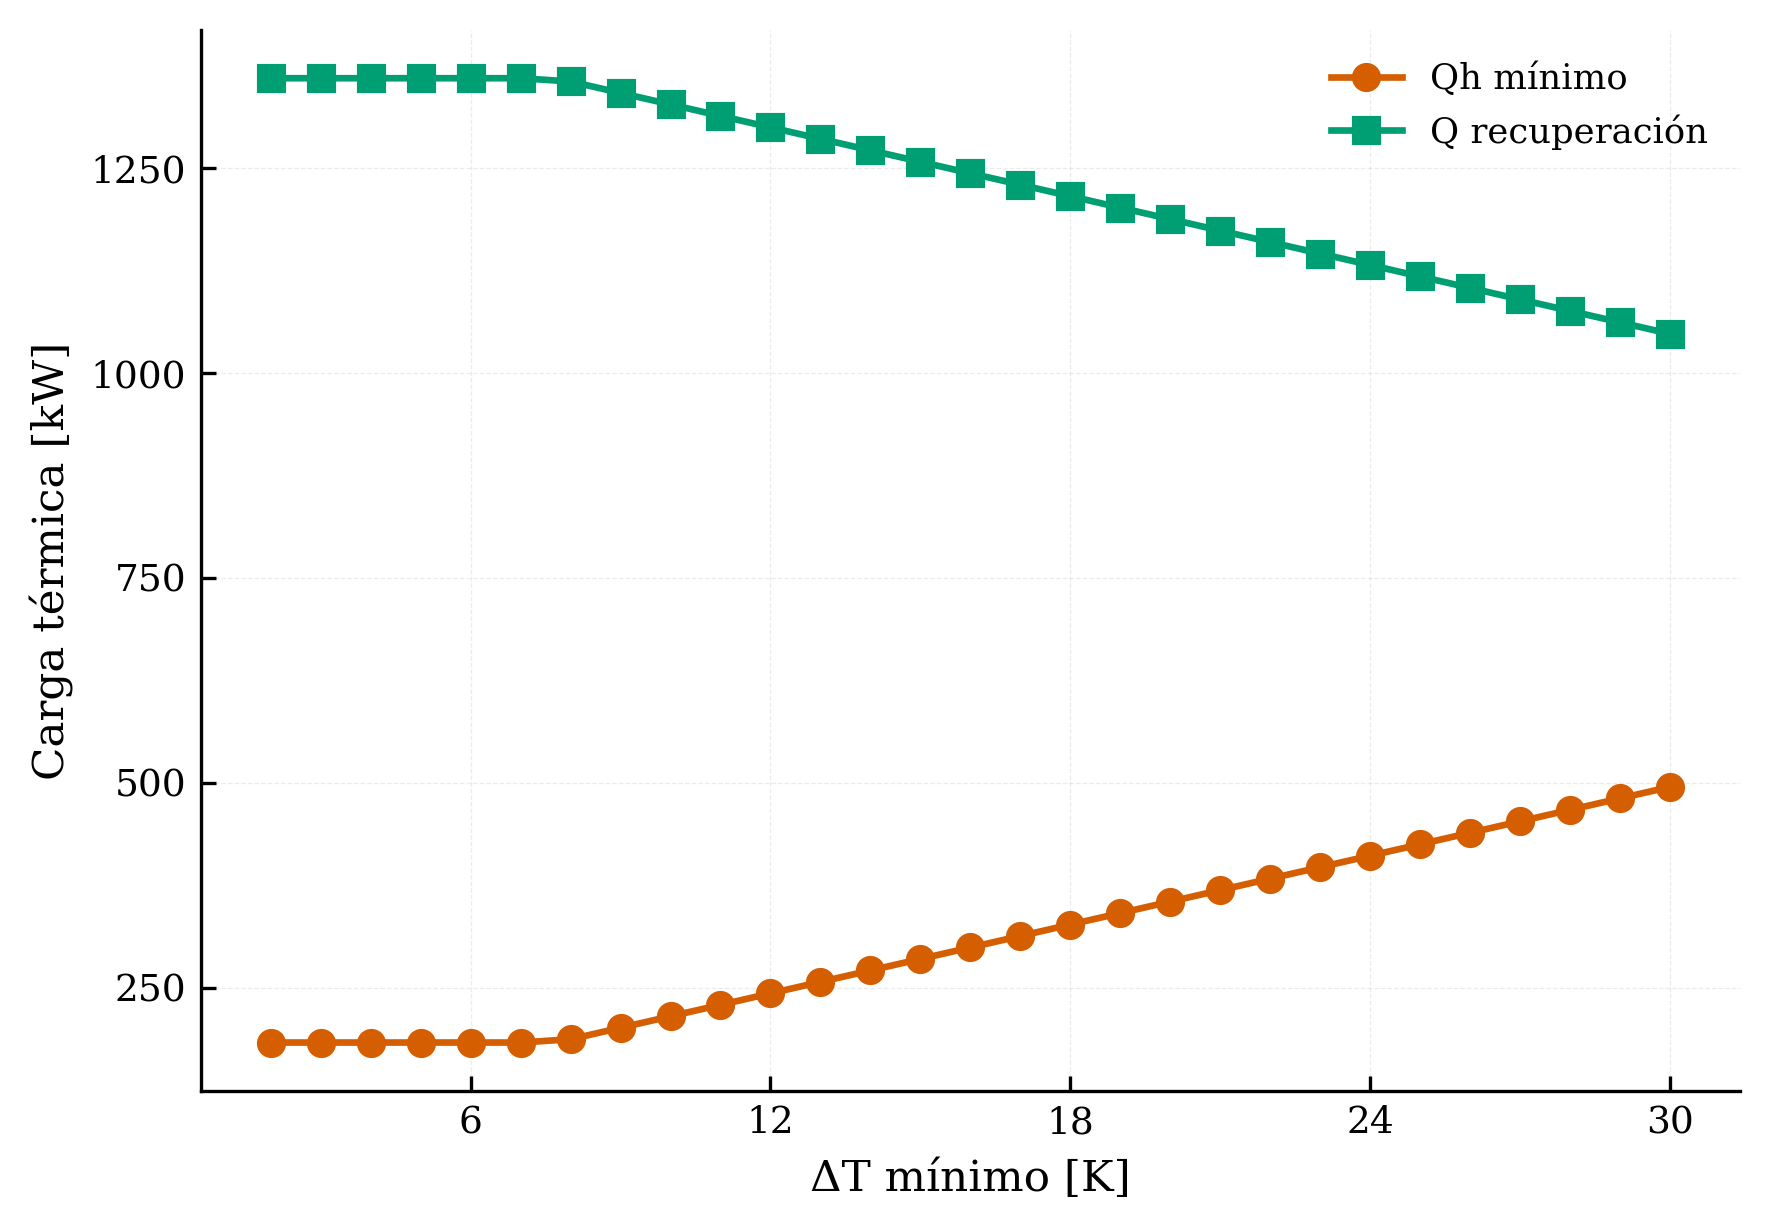

In [34]:
fig_tradeoff = plot_tradeoff(sweep_table)

## S3. La escalera solar

Una fuente solar a nivel T solo puede desplazar el servicio caliente que el proceso necesita por debajo de T. La escalera entrega, para cada nivel de suministro, la carga desplazada, la fraccion que representa del servicio caliente minimo y el margen al pliegue de la compuesta caliente.

La seleccion del nivel no vive aqui: vive en NB3, con la regla del menor nivel del conjunto que satura el servicio caliente minimo dentro de 1e-6 kW. Cuando ningun nivel satura, la cobertura parcial se imprime como premisa del caso y no como resultado del motor.

In [36]:
staircase = solar_staircase(streams, result, dt_cont_K=5.0)

In [37]:
for step in staircase.steps:
    print(
        f"Nivel {step.level_C:>6.1f} °C, absorbido {step.absorbed_kW:>7.1f} kW, "
        f"fraccion {step.fraction_frac:.4f}, margen al pliegue {step.pinch_margin_K:+.1f} K"
    )
print(f"Nivel de saturacion del conjunto suministrado: {staircase.saturation_level_C:.1f} °C")

Nivel  120.0 °C, absorbido     0.0 kW, fraccion 0.0000, margen al pliegue -7.0 K
Nivel  140.0 °C, absorbido    91.0 kW, fraccion 0.4233, margen al pliegue +13.0 K
Nivel  160.0 °C, absorbido   167.0 kW, fraccion 0.7767, margen al pliegue +33.0 K
Nivel  180.0 °C, absorbido   215.0 kW, fraccion 1.0000, margen al pliegue +53.0 K
Nivel  250.0 °C, absorbido   215.0 kW, fraccion 1.0000, margen al pliegue +123.0 K
Nivel de saturacion del conjunto suministrado: 180.0 °C


## S4. El nivel de saturacion no es una constante fisica

`saturation_level_C` es el menor nivel del conjunto suministrado que satura, y no una constante fisica del proceso. Con el conjunto por defecto vale 180.0 °C, mientras que el inicio fisico medido de la saturacion es 169.6 °C.

La lectura correcta en clase es que satura desde 180.0 °C en este conjunto, nunca que satura a 180.0 °C.

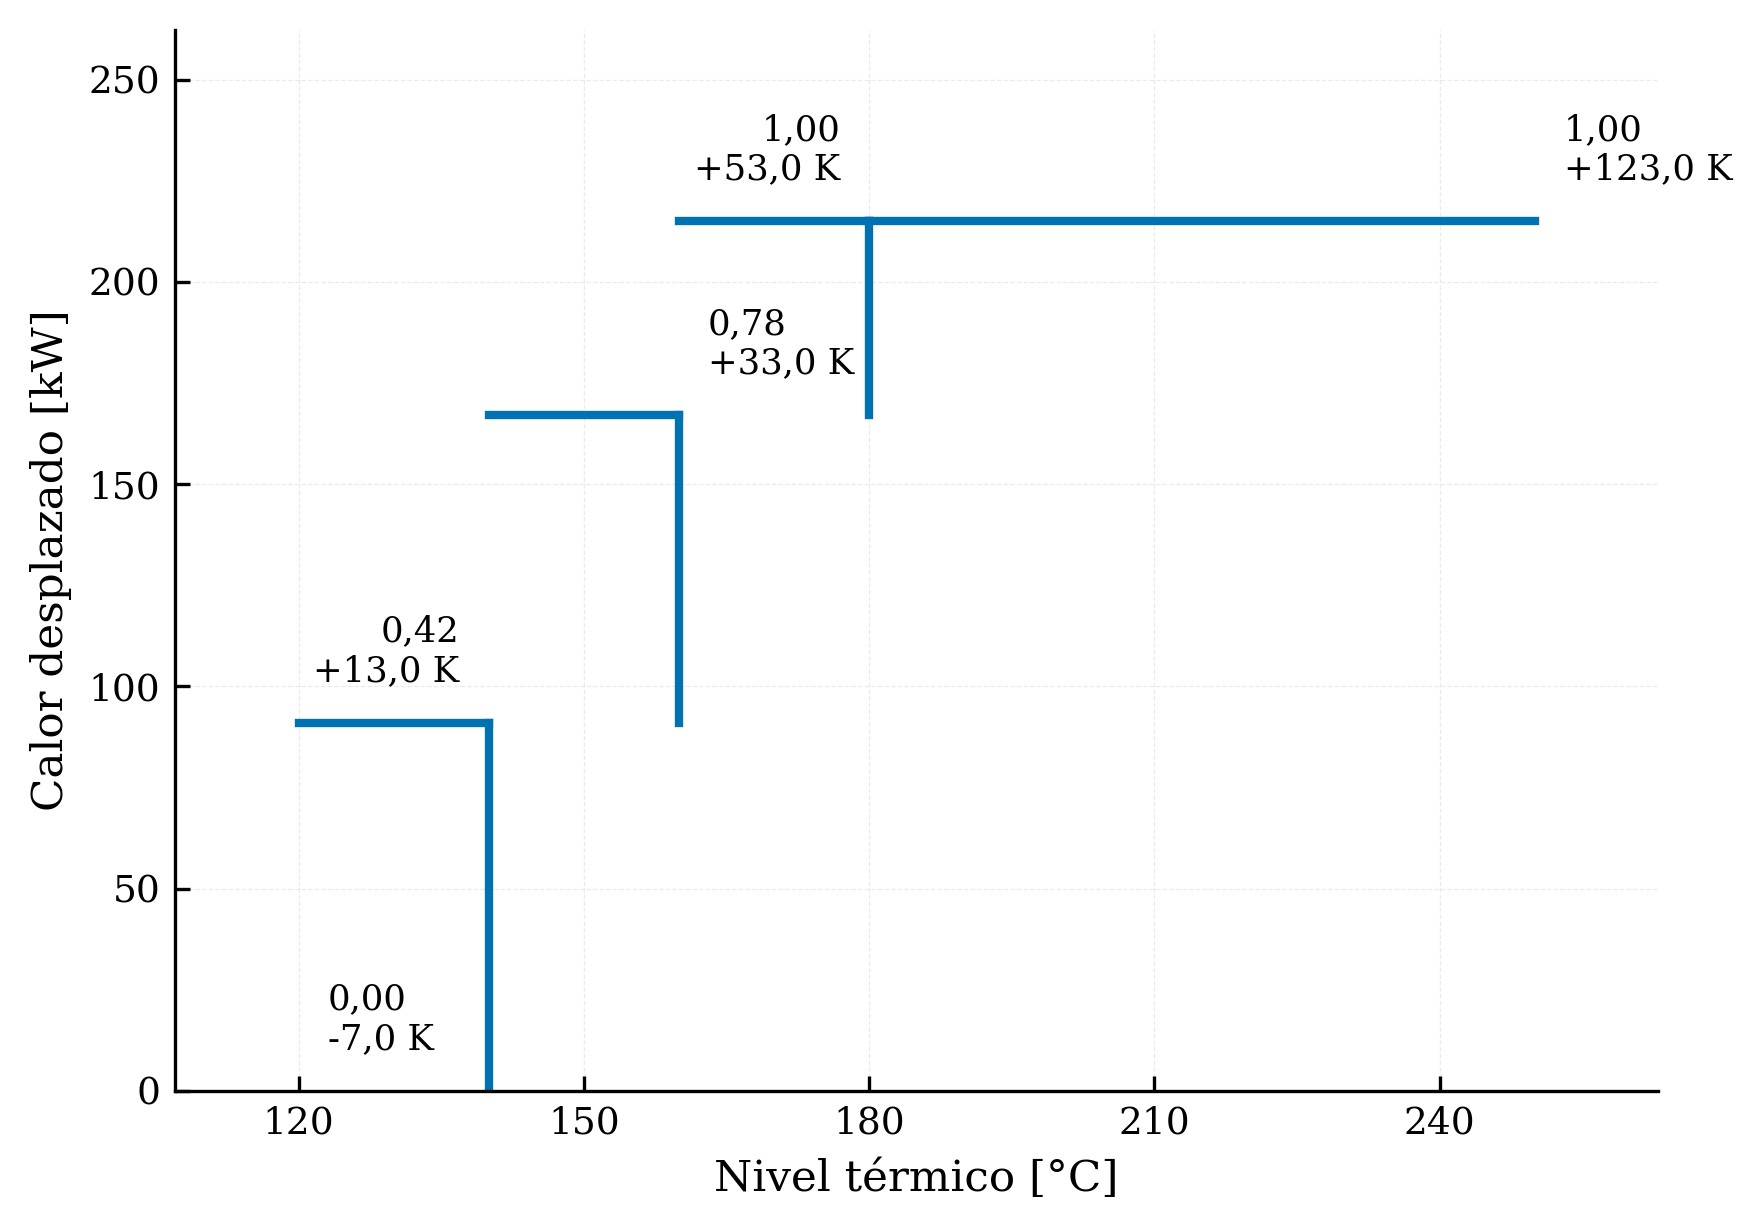

In [39]:
fig_staircase = plot_solar_staircase(staircase)

## S5. Que ensenan las dos figuras

La figura de compromiso muestra que abrir la aproximacion compra superficie y vende servicio. La escalera muestra que los ultimos 30 grados por encima de 180 °C no compran nada: el peldaño ya vale lo mismo que el anterior.

Ningun nivel se elige en este cuaderno, y el area no es una magnitud de este cuaderno.